In [162]:
!pip install tqdm

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/676.6 kB ? eta -:--:--
   ---------------------------------------- 0.0/676.6 kB ? eta -:--:--
   ---------------------------------------- 0.0/676.6 kB ? eta -:--:--
   --------------- ------------------------ 262.1/676.6 kB ? eta -:--:--
   --------------- ------------------------ 262.1/676.6 kB ? eta -:--:--
   ---------------------------------------- 676.6/676.6 kB 883.9 kB/s  0:00:01


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [168]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import warnings
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, cross_val_predict
from tqdm import tqdm

In [169]:
filepath="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"
df = pd.read_csv(filepath)
df.head()

,Unnamed: 0.1,Unnamed: 0,Manufacturer,Category,GPU,OS,CPU_core,Screen_Size_inch,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_pounds,Price,Price-binned,Screen-Full_HD,Screen-IPS_panel
0,0,0,Acer,4,2,1,5,14.0,0.551724,8,256,3.52800,978,Low,0,1
1,1,1,Dell,3,1,1,3,15.6,0.689655,4,256,4.85100,634,Low,1,0
2,2,2,Dell,3,1,1,7,15.6,0.931034,8,256,4.85100,946,Low,1,0
3,3,3,Dell,4,2,1,5,13.3,0.551724,8,128,2.69010,1244,Low,0,1
4,4,4,HP,4,2,1,7,15.6,0.620690,8,256,4.21155,837,Low,1,0


In [170]:
headers=["?","??","Manufacturer", "Category", "GPU", "OS", "CPU_core","Screen_Size_inch", "CPU_frequency", "RAM_GB", "Storage_GB_SSD", "Weight_pounds", "Price", "Price-binned", "Screen-Full_HD","Screen-IPS_panel"]
df.columns= headers
df.head(5)

,?,??,Manufacturer,Category,GPU,OS,CPU_core,Screen_Size_inch,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_pounds,Price,Price-binned,Screen-Full_HD,Screen-IPS_panel
0,0,0,Acer,4,2,1,5,14.0,0.551724,8,256,3.52800,978,Low,0,1
1,1,1,Dell,3,1,1,3,15.6,0.689655,4,256,4.85100,634,Low,1,0
2,2,2,Dell,3,1,1,7,15.6,0.931034,8,256,4.85100,946,Low,1,0
3,3,3,Dell,4,2,1,5,13.3,0.551724,8,128,2.69010,1244,Low,0,1
4,4,4,HP,4,2,1,7,15.6,0.620690,8,256,4.21155,837,Low,1,0


In [171]:
df.dtypes

?                     int64
??                    int64
Manufacturer            str
Category              int64
GPU                   int64
OS                    int64
CPU_core              int64
Screen_Size_inch    float64
CPU_frequency       float64
RAM_GB                int64
Storage_GB_SSD        int64
Weight_pounds       float64
Price                 int64
Price-binned            str
Screen-Full_HD        int64
Screen-IPS_panel      int64
dtype: object

## **SIMPLE LINEAR REGRESSION**

In [172]:
lm=LinearRegression()
X=df[['CPU_frequency']]
Y=df['Price']

In [173]:
lm.fit(X, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1485.19]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['CPU_frequency']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,253.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [174]:
Y_predict=lm.predict(X)

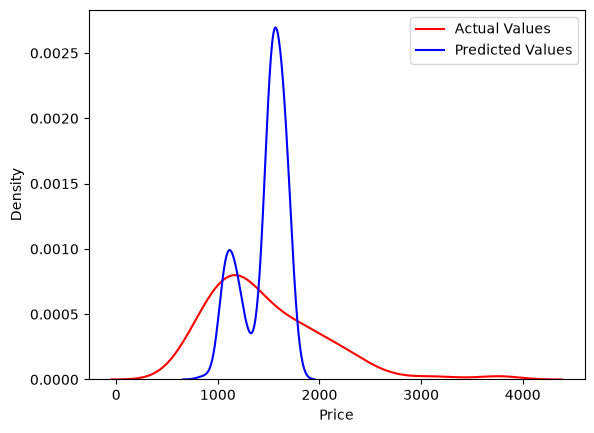

In [175]:
ax1=sns.kdeplot(data=Y, color="r", label="Actual Values")
sns.kdeplot(data=Y_predict, color="b", label="Predicted Values", ax=ax1)
plt.legend()
plt.show()

<Axes: xlabel='Price'>

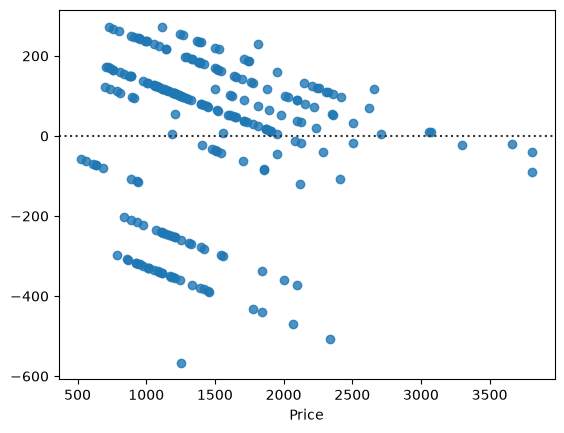

In [176]:
sns.residplot(x=Y, y=Y_predict)

In [177]:
r2=r2_score(Y, Y_predict)
mse=mean_squared_error(Y, Y_predict)
print("Le r2 est: ",r2, " et le MSE est: ", mse)

Le r2 est:  0.1344436321024326  et le MSE est:  284583.4405868629


## **MULTIPLE LINEAR REGRESSION**

In [178]:
lm1=LinearRegression()
Z = df[['CPU_frequency','RAM_GB','Storage_GB_SSD','CPU_core','OS','GPU','Category']]

In [179]:
lm1.fit(Z, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 961.28, 86.81, 0.39,...,-427.45, 97.8 , 191.3 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['CPU_frequency','RAM_GB','Storage_GB_SSD',...,'OS','GPU','Category']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-842
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [180]:
Y1_predict=lm1.predict(Z)

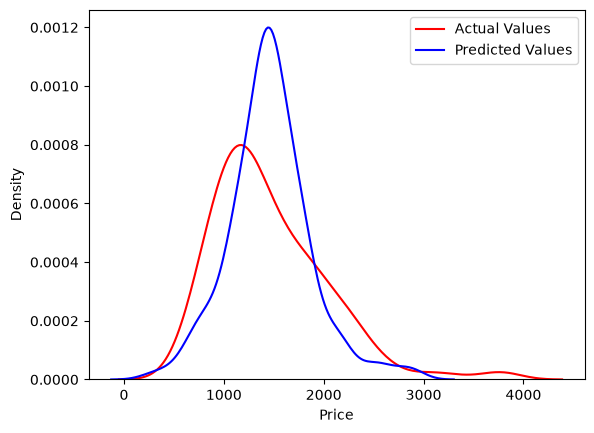

In [181]:
ax1=sns.kdeplot(data=Y, color="r", label="Actual Values")
sns.kdeplot(data=Y1_predict, color="b", label="Predicted Values", ax=ax1)
plt.legend()
plt.show()

<Axes: xlabel='Price'>

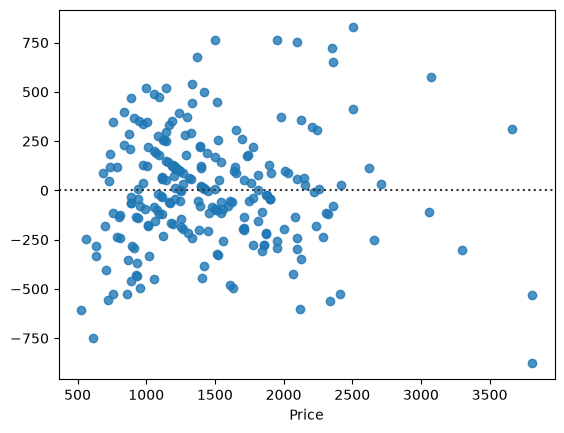

In [182]:
sns.residplot(x=Y, y=Y1_predict)

In [183]:
r2=r2_score(Y, Y1_predict)
mse=mean_squared_error(Y, Y1_predict)
print("Le r2 est: ",r2, " et le MSE est: ", mse)

Le r2 est:  0.5082509055187376  et le MSE est:  161680.57263893104


## **POLYNOMIAL REGRESSION**

In [184]:
model=make_pipeline(
    PolynomialFeatures(degree=5),
    StandardScaler(),
    LinearRegression()
)

In [185]:
model.fit(X, Y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['CPU_frequency']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",5
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


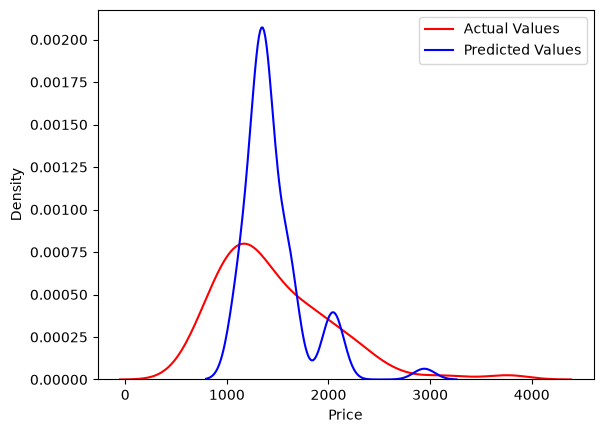

In [186]:
Y2_predict=model.predict(X)
ax1=sns.kdeplot(data=Y, color="r", label="Actual Values")
sns.kdeplot(data=Y2_predict, color="b", label="Predicted Values", ax=ax1)
plt.legend()
plt.show()

In [187]:
r2=r2_score(Y, Y2_predict)
mse=mean_squared_error(Y, Y2_predict)
print("Le r2 est: ",r2, " et le MSE est: ", mse)

Le r2 est:  0.30308227064439863  et le MSE est:  229137.29548053225


## **MODEL EVALUATION AND REFINEMENT**

In [188]:
path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/module_5_auto.csv'
df = pd.read_csv(path)
df.head(5)

,Unnamed: 0.1,Unnamed: 0,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,0,0,3,122,alfa-romero,std,two,convertible,rwd,front,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,1,1,3,122,alfa-romero,std,two,convertible,rwd,front,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,2,2,1,122,alfa-romero,std,two,hatchback,rwd,front,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,3,3,2,164,audi,std,four,sedan,fwd,front,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,4,4,2,164,audi,std,four,sedan,4wd,front,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [189]:
df_numerical=df._get_numeric_data()
df_numerical.info

<bound method DataFrame.info of      Unnamed: 0.1  Unnamed: 0  symboling  normalized-losses  wheel-base  \
0               0           0          3                122        88.6   
1               1           1          3                122        88.6   
2               2           2          1                122        94.5   
3               3           3          2                164        99.8   
4               4           4          2                164        99.4   
..            ...         ...        ...                ...         ...   
196           196         196         -1                 95       109.1   
197           197         197         -1                 95       109.1   
198           198         198         -1                 95       109.1   
199           199         199         -1                 95       109.1   
200           200         200         -1                 95       109.1   

       length     width  height  curb-weight  engine-size  ...  str

In [190]:
Y=df_numerical['price']
X=df_numerical.drop('price', axis=1)

In [207]:
x_train, x_test, y_train, y_test= train_test_split(X, Y, test_size=0.10, random_state=42)

In [192]:
print("the training set size is: ",x_train.shape[0])
print("the test set size is : ", x_test.shape[0])

the training set size is:  180
the test set size is :  21


In [195]:
lr1=LinearRegression()
lr1.fit(x_train[['horsepower']], y_train)
y_predict1=lr1.predict(x_train[['horsepower']])
r2=r2_score(y_train, y_predict1)

y_predict1_test=lr1.predict(x_test[['horsepower']])
r2_test=r2_score(y_test, y_predict1_test)
print('the r2 score for training is : ',r2,' and the r2 score for testing is : ', r2_test)

the r2 score for training is :  0.6385840105530061  and the r2 score for testing is :  0.6572835188314445


In [196]:
lr2=LinearRegression()
cross=cross_val_score(lr2, x_train[['horsepower']], y_train, cv=2)
cross

array([0.63161061, 0.62163752])

In [197]:
print("The mean of the folds are", cross.mean(), "and the standard deviation is" , cross.std())

The mean of the folds are 0.6266240658591489 and the standard deviation is 0.004986543188712389


In [198]:
y_predicts=cross_val_predict(lr2, x_train[['horsepower']], y_train, cv=4)

In [199]:
y_predicts[0:5]

array([24819.5651911 ,  6611.70575548,  7673.83088923, 15867.36763526,
        6915.17007941])

## **Overfitting, Underfitting and Model Selection**

In [200]:
lr3=LinearRegression()
lr3.fit(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[47.23, 4.62,74.1 , 6.32]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['horsepower','curb-weight','engine-size','highway-mpg']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.321e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


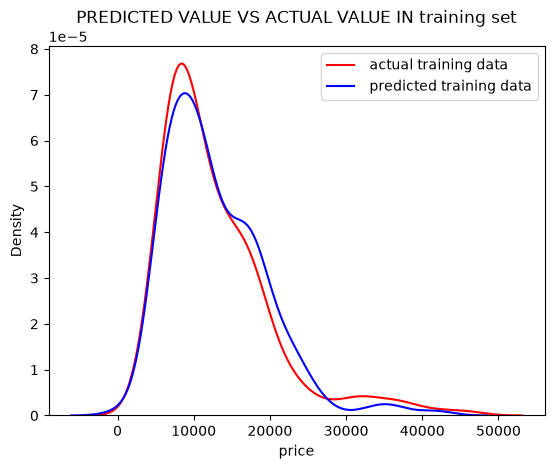

In [201]:
y_predict3 = lr3.predict(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
y_predict3_test = lr3.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

sns.kdeplot(data=y_train ,color='r', label=" actual training data")
sns.kdeplot(data=y_predict3 ,color='b', label=" predicted training data")
plt.legend()
plt.title("PREDICTED VALUE VS ACTUAL VALUE IN training set")
plt.show()

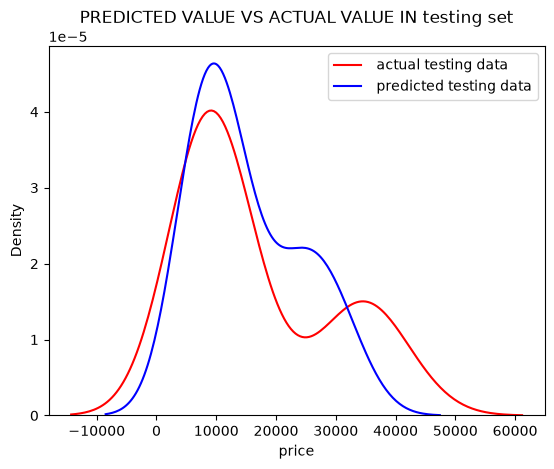

In [202]:
sns.kdeplot(data=y_test ,color='r', label=" actual testing data")
sns.kdeplot(data=y_predict3_test ,color='b', label=" predicted testing data")
plt.legend()
plt.title("PREDICTED VALUE VS ACTUAL VALUE IN testing set")
plt.show()

* now let see overfitting with polynomial degree

In [208]:
x_train.columns
x_train.drop('Unnamed: 0.1', axis=1, inplace=True)
x_train.drop('Unnamed: 0', axis=1, inplace=True)
x_test.drop('Unnamed: 0.1', axis=1, inplace=True)
x_test.drop('Unnamed: 0', axis=1, inplace=True)


In [209]:
x_train.fillna({'stroke': x_train['stroke'].mode()[0]}, inplace=True)

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,city-L/100km,diesel,gas
16,0,122,110.0,0.946660,0.984722,56.3,3505,209,3.62,3.39,8.0,182.0,5400.0,15,20,15.666667,0,1
148,1,74,95.7,0.762614,0.883333,54.5,2015,92,3.05,3.03,9.0,62.0,4800.0,31,38,7.580645,0,1
93,1,122,94.5,0.794330,0.886111,54.5,1971,97,3.15,3.29,9.4,69.0,5200.0,31,37,7.580645,0,1
65,-1,93,110.0,0.917347,0.976389,58.7,3750,183,3.58,3.64,21.5,123.0,4350.0,22,25,10.681818,1,0
60,0,122,98.8,0.854397,0.923611,55.5,2443,122,3.39,3.39,22.7,64.0,4650.0,36,42,6.527778,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,0,122,114.2,0.955790,0.950000,58.7,3230,120,3.46,3.19,8.4,97.0,5000.0,19,24,12.368421,0,1
14,0,122,103.5,0.908217,0.929167,55.7,3230,209,3.62,3.39,8.0,182.0,5400.0,16,22,14.687500,0,1
92,1,128,94.5,0.795771,0.886111,53.3,2028,97,3.15,3.29,9.4,69.0,5200.0,31,37,7.580645,0,1
179,2,122,97.3,0.825084,0.909722,55.7,2209,109,3.19,3.40,9.0,85.0,5250.0,27,34,8.703704,0,1


In [210]:
pipe=make_pipeline(
    PolynomialFeatures(degree=5),
    StandardScaler(),
    LinearRegression()
)

In [211]:
pipe.fit(x_train, y_train)
y_predicts=pipe.predict(x_train)
y_predicts_test=pipe.predict(x_test)

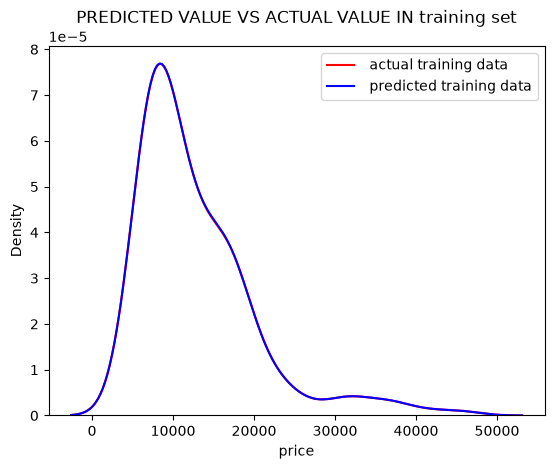

In [212]:
sns.kdeplot(data=y_train ,color='r', label=" actual training data")
sns.kdeplot(data=y_predicts ,color='b', label=" predicted training data")
plt.legend()
plt.title("PREDICTED VALUE VS ACTUAL VALUE IN training set")
plt.show()

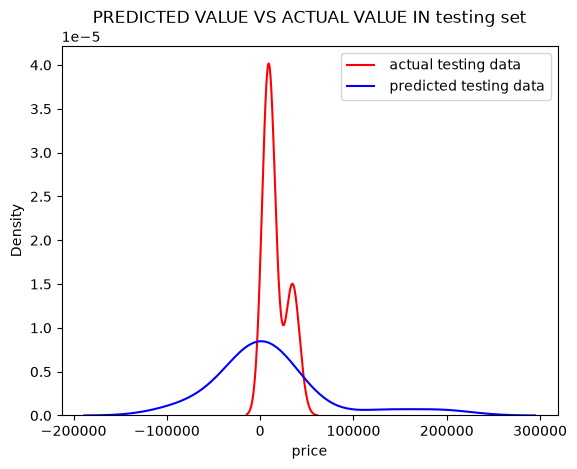

In [213]:
sns.kdeplot(data=y_test ,color='r', label=" actual testing data")
sns.kdeplot(data=y_predicts_test ,color='b', label=" predicted testing data")
plt.legend()
plt.title("PREDICTED VALUE VS ACTUAL VALUE IN testing set")
plt.show()

In [214]:
r2=r2_score(y_train, y_predicts)
r2_test=r2_score(y_test, y_predicts_test)
print("Le r2 score pour le training est: ",r2, " et le r2 pour le testing est: ",r2_test)

Le r2 score pour le training est:  0.999111005032019  et le r2 pour le testing est:  -21.680058807431525


Text(0.5, 1.0, 'R^2 Using Test Data')

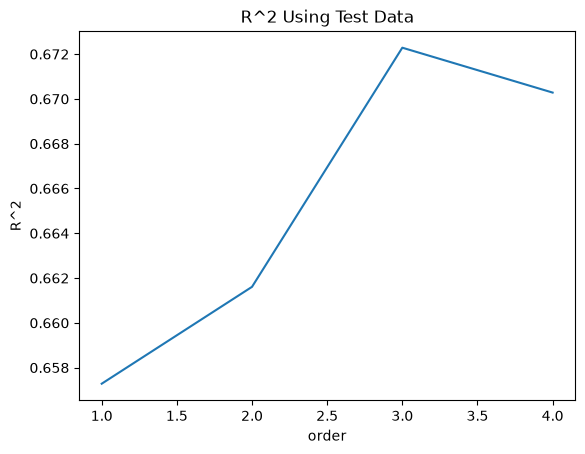

In [215]:
Rsqu_test = []

order = [1, 2, 3, 4]
for i in order:
    pipe=make_pipeline(
        PolynomialFeatures(degree=i),
        StandardScaler(),
        LinearRegression()
    )
    pipe.fit(x_train[['horsepower']], y_train)
    y_predicts_test=pipe.predict(x_test[['horsepower']])
    r2_test=r2_score( y_test, y_predicts_test)
    Rsqu_test.append(r2_test)

plt.plot(order, Rsqu_test)
plt.xlabel('order')
plt.ylabel('R^2')
plt.title('R^2 Using Test Data')

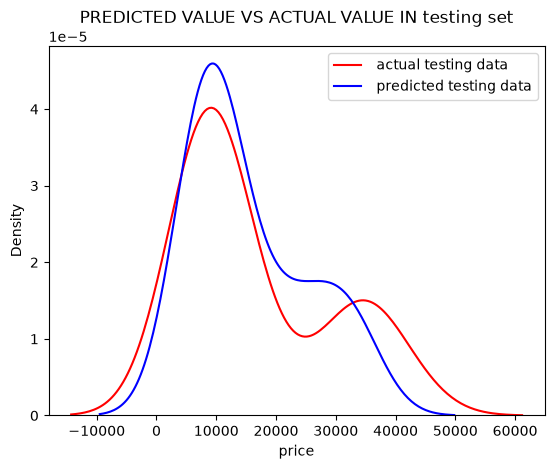

In [216]:
pipe=make_pipeline(
        PolynomialFeatures(degree=2),
        StandardScaler(),
        LinearRegression()
    )
pipe.fit(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_train)
y_predicts_test=pipe.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

sns.kdeplot(data=y_test ,color='r', label=" actual testing data")
sns.kdeplot(data=y_predicts_test ,color='b', label=" predicted testing data")
plt.legend()
plt.title("PREDICTED VALUE VS ACTUAL VALUE IN testing set")
plt.show()

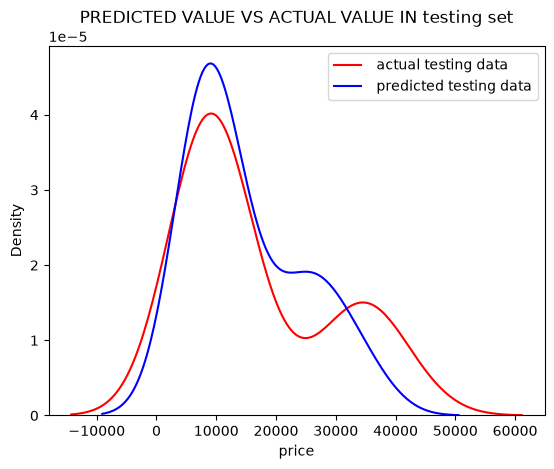

In [217]:
pipe=make_pipeline(
        PolynomialFeatures(degree=2),
        StandardScaler(),
        Ridge(alpha=1)
    )
pipe.fit(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']], y_train)
y_predicts_test=pipe.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']])

sns.kdeplot(data=y_test ,color='r', label=" actual testing data")
sns.kdeplot(data=y_predicts_test ,color='b', label=" predicted testing data")
plt.legend()
plt.title("PREDICTED VALUE VS ACTUAL VALUE IN testing set")
plt.show()

In [220]:
Rsqu_test = []
Rsqu_train = []
dummy1 = []
Alpha = 10 * np.array(range(0,1000))
pbar = tqdm(Alpha)

for alpha in pbar:
    pipe=make_pipeline(
        PolynomialFeatures(degree=2),
        StandardScaler(),
        Ridge(alpha=alpha)
    )
    pipe.fit(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']], y_train)
    y_predict=pipe.predict(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']])
    y_predicts_test=pipe.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']])
    test_score, train_score = r2_score(y_test, y_predicts_test), r2_score(y_train, y_predict)
    
    pbar.set_postfix({"Test Score": test_score, "Train Score": train_score})

    Rsqu_test.append(test_score)
    Rsqu_train.append(train_score)

100%|██████████| 1000/1000 [00:15<00:00, 64.60it/s, Test Score=0.131, Train Score=0.247]


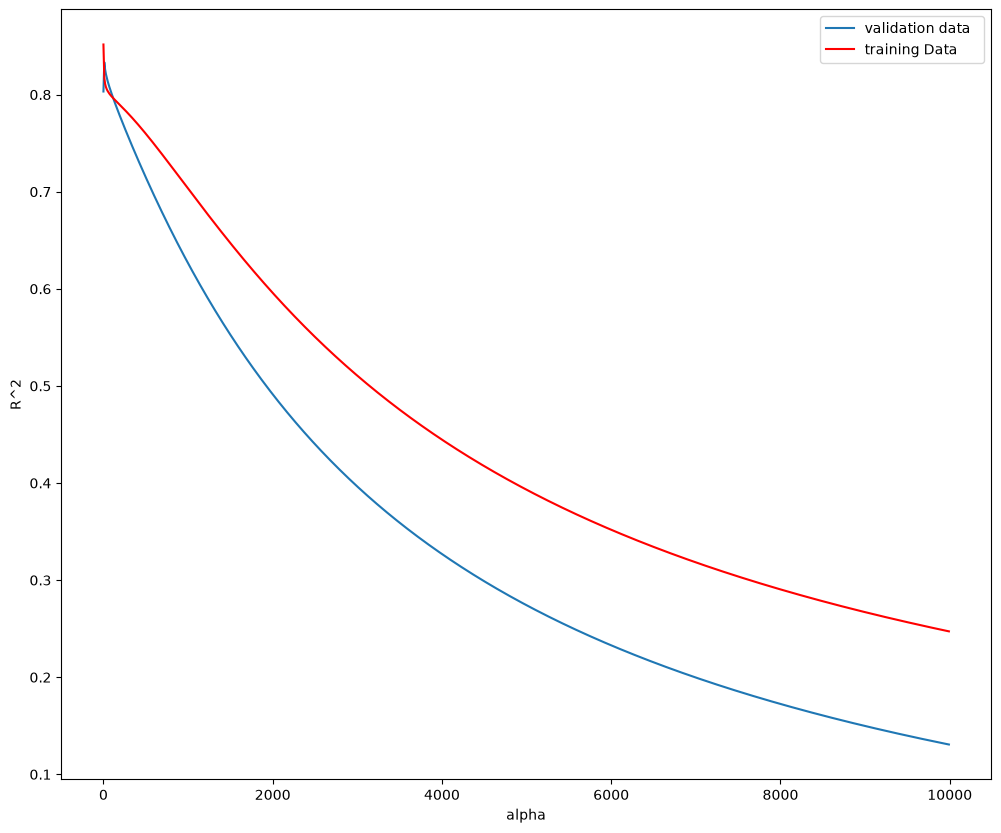

In [221]:
width = 12
height = 10
plt.figure(figsize=(width, height))

plt.plot(Alpha,Rsqu_test, label='validation data  ')
plt.plot(Alpha,Rsqu_train, 'r', label='training Data ')
plt.xlabel('alpha')
plt.ylabel('R^2')
plt.legend()

In [223]:
pipe=make_pipeline(
        PolynomialFeatures(degree=2),
        StandardScaler(),
        Ridge(alpha=10)
    )
pipe.fit(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']], y_train)
y_predicts_test=pipe.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']])

r2_score(y_test, y_predicts_test)

0.8333686055742036

* GRID SEARCH

In [229]:
parameters1= [{"polynomialfeatures__degree": [1, 2, 3, 4, 5],'ridge__alpha': [0.001,0.1,1, 10, 100, 1000, 10000, 100000, 100000]}]
parameters1

[{'polynomialfeatures__degree': [1, 2, 3, 4, 5],
  'ridge__alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000, 100000]}]

In [230]:
pipe=make_pipeline(
    PolynomialFeatures(),
    StandardScaler(),
    Ridge()
)

grid1 = GridSearchCV(pipe, parameters1,cv=4)

grid1.fit(X[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], Y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'polynomialfeatures__degree': [1, 2, ...], 'ridge__alpha': [0.001, 0.1, ...]}]"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the v

In [233]:
best= grid1.best_estimator_
best

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['horsepower','curb-weight','engine-size','highway-mpg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",3
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [237]:
y_predict=best.predict(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
y_predict_test=best.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

r2=r2_score(y_train, y_predict)
r2_test=r2_score(y_test, y_predict_test)
print("The r2 score for training is:", r2, " and for testing is: ", r2_test)

The r2 score for training is: 0.777832382396023  and for testing is:  0.7762951171345955


In [241]:
best_alpha=grid1.best_params_['ridge__alpha']
best_degree=grid1.best_params_['polynomialfeatures__degree']


print("The best alpha is:", best_alpha, " and the best degree is: ", best_degree)

The best alpha is: 1000  and the best degree is:  3


## **MODEL REFINEMENT AND EVALUATION TEST**

In [247]:
filepath = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv'
df = pd.read_csv(filepath)
df.drop('Unnamed: 0.1', axis=1, inplace=True)
df.drop('Unnamed: 0', axis=1, inplace=True)
df.columns

Index(['Manufacturer', 'Category', 'GPU', 'OS', 'CPU_core', 'Screen_Size_inch',
       'CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'Weight_pounds', 'Price',
       'Price-binned', 'Screen-Full_HD', 'Screen-IPS_panel'],
      dtype='str')

* # Task 1 : Using Cross validation to improve the model

In [250]:
Y=df['Price']
X=df.drop('Price', axis=1)

In [253]:
x_train, x_test, y_train, y_test= train_test_split(X, Y, test_size=0.10, random_state=42)
x_train.shape[0], x_test.shape[0]

(214, 24)

In [254]:
lr1=LinearRegression()
lr1.fit(x_train[['CPU_frequency']], y_train)
y_predict=lr1.predict(x_train[['CPU_frequency']])
y_predict_test=lr1.predict(x_test[['CPU_frequency']])

r2_score(y_train, y_predict), r2_score(y_test, y_predict_test)

(0.14704575896482774, -0.4706643218948636)

In [256]:
cross=cross_val_score(lr1, x_train[['CPU_frequency']], y_train, cv=4)
cross ,cross.mean(), cross.std()

(array([0.21470429, 0.07668697, 0.09660439, 0.19860238]),
 np.float64(0.14664950700435947),
 np.float64(0.06068324314751394))

* # Task 2: Overfitting

In [257]:
x_train, x_test, y_train, y_test= train_test_split(X, Y, test_size=0.50, random_state=42)
x_train.shape[0], x_test.shape[0]

(119, 119)

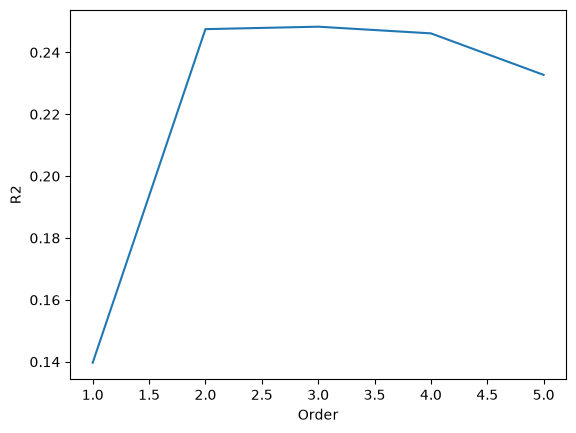

In [264]:
r2_test=[]
degree=[1,2,3,4,5]
for i in degree:
    pipe=make_pipeline(
        PolynomialFeatures(degree=i),
        StandardScaler(),
        LinearRegression()
    )
    pipe.fit(x_train[['CPU_frequency']], y_train)
    y_predicted=pipe.predict(x_test[['CPU_frequency']])
    r2_test.append(r2_score(y_test, y_predicted))

plt.plot(degree, r2_test, label="R2 scores for each degree")
plt.xlabel("Order")
plt.ylabel("R2")
plt.show()

* # Task 3 : Ridge Regression

In [268]:
alpha = np.arange(0.001, 1.001, 0.001)
r2_train=[]
r2_test=[]

for i in alpha:
    pipe=make_pipeline(
        PolynomialFeatures(degree=2),
        StandardScaler(),
        Ridge(alpha=i)
    )
    pipe.fit(x_train[['CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'CPU_core', 'OS', 'GPU', 'Category']], y_train)

    y_predict_train=pipe.predict(x_train[['CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'CPU_core', 'OS', 'GPU', 'Category']])
    y_predict_test=pipe.predict(x_test[['CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'CPU_core', 'OS', 'GPU', 'Category']])
    r2_train.append(r2_score(y_train, y_predict_train))
    r2_test.append(r2_score(y_test, y_predict_test))


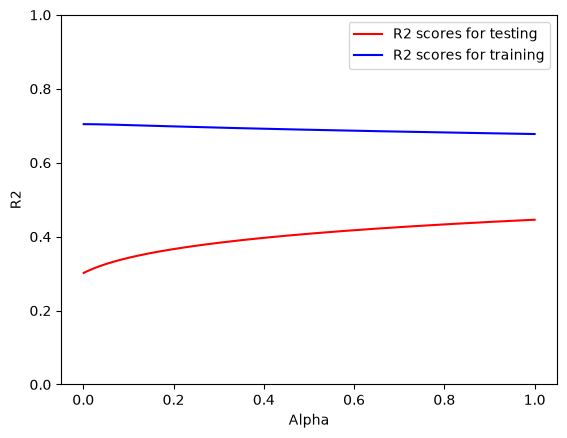

In [270]:
plt.plot(alpha, r2_test,"r", label="R2 scores for testing")
plt.plot(alpha, r2_train,"b", label="R2 scores for training")
plt.ylim(0,1)
plt.legend()
plt.xlabel("Alpha")
plt.ylabel("R2")
plt.show()

* # Task 4: Grid Search

In [271]:
parameters=[{'ridge__alpha':[0.0001, 0.001, 0.01, 0.1, 1, 5,10]}]
pipe=make_pipeline(
    PolynomialFeatures(degree=2),
    StandardScaler(),
    Ridge()
)

grid=GridSearchCV(pipe, parameters, cv=4)

In [277]:
grid.fit(x_train[['CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'CPU_core', 'OS', 'GPU', 'Category']], y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'ridge__alpha': [0.0001, 0.001, ...]}]"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during f

In [278]:
best=grid.best_estimator_

In [281]:
y_predict=best.predict(x_test[['CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'CPU_core', 'OS', 'GPU', 'Category']])
r2=r2_score(y_test, y_predict)
r2

0.44584179428239135